In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.model_selection import train_test_split, KFold
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.inspection import PartialDependenceDisplay
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.tree import DecisionTreeRegressor
import matplotlib.font_manager as fm
import seaborn as sns
import os



In [2]:
#폰트 출력
font_list = [font.name for font in fm.fontManager.ttflist]
font_list

['STIXGeneral',
 'STIXNonUnicode',
 'STIXSizeFourSym',
 'STIXSizeFiveSym',
 'cmtt10',
 'STIXSizeOneSym',
 'DejaVu Sans Display',
 'STIXSizeTwoSym',
 'cmr10',
 'STIXSizeThreeSym',
 'DejaVu Sans',
 'DejaVu Serif',
 'STIXSizeFourSym',
 'STIXNonUnicode',
 'STIXSizeOneSym',
 'DejaVu Sans',
 'DejaVu Sans Mono',
 'STIXSizeTwoSym',
 'DejaVu Sans',
 'cmex10',
 'STIXNonUnicode',
 'cmmi10',
 'DejaVu Serif',
 'DejaVu Serif Display',
 'STIXSizeThreeSym',
 'DejaVu Serif',
 'DejaVu Sans Mono',
 'DejaVu Serif',
 'STIXGeneral',
 'DejaVu Sans',
 'cmss10',
 'STIXNonUnicode',
 'cmb10',
 'STIXGeneral',
 'cmsy10',
 'STIXGeneral',
 'DejaVu Sans Mono',
 'DejaVu Sans Mono',
 'Gill Sans MT Condensed',
 'HYPost-Medium',
 'Pristina',
 'Trebuchet MS',
 'Consolas',
 'Century Gothic',
 'Broadway',
 'Microsoft Uighur',
 'Arial',
 'Microsoft New Tai Lue',
 'Rockwell Condensed',
 'Sitka Small',
 'Segoe Print',
 'Ebrima',
 'Calisto MT',
 'Elephant',
 'Malgun Gothic',
 'Verdana',
 'MS Mincho',
 'Berlin Sans FB',
 'Dubai'

건축경과일 추가 코드

In [3]:
df = pd.read_csv("seoul_with_city_gu_dong.csv")

In [4]:
df.isnull().sum()

id             0
lat            0
lng            0
households     0
buildDate      0
score          0
m2             0
p              0
min_sales     90
max_sales     90
avg_sales     90
address        0
city           4
gu            61
dong          10
dtype: int64

In [5]:
missing_city_rows = df[(df['gu'].isna()) | (df['gu'].str.strip() == "")]
print(missing_city_rows)

         id        lat         lng  households  buildDate  score  m2   p  \
16    19849  37.690017  127.053827         473     200908    4.4  75  23   
18    19848  37.689693  127.052271         680     200908    4.0  78  24   
76     2089  37.702391  127.048280         146     199901    3.9  78  24   
77     7531  37.703007  127.048339         281     199811    4.4  79  24   
78     7530  37.704038  127.049043         700     200311    4.2  98  30   
...     ...        ...         ...         ...        ...    ...  ..  ..   
3731   6407  37.491776  126.867388         442     200502    4.0  78  24   
3739     89  37.490658  126.867048         841     199802    4.1  84  25   
3750  15445  37.488768  126.865729         900     200703    4.0  79  24   
3757    884  37.489037  126.868190         900     199001    3.6  72  22   
3767   1015  37.486128  126.869665         500     198510    3.1  43  13   

      min_sales  max_sales  avg_sales  \
16      24100.0    39100.0    28500.0   
18   

In [6]:
missing_dong = df[(df['dong'].isna()) | (df['dong'].str.strip() == "")]
print(missing_dong)

         id        lat         lng  households  buildDate  score   m2   p  \
452   18929  37.599503  127.129030         276     200904    4.2  108  33   
468   26072  37.602241  127.130009         171     201505    4.2  100  30   
475   26236  37.603203  127.130681         236     201505    4.2  111  34   
491    8480  37.602536  127.133416         207     198910    2.8   75  23   
505    6297  37.607359  127.133289         572     200411    4.2   80  24   
536   18281  37.599245  127.031050         955     200910    4.2   84  25   
586   19318  37.599481  127.038830        1025     201101    4.4   81  25   
687   18281  37.599245  127.031050         955     200910    4.2   84  25   
737   19318  37.599481  127.038830        1025     201101    4.4   81  25   
1306  10495  35.885938  128.596203         977     200605    4.6  109  33   

      min_sales  max_sales  avg_sales  \
452     40200.0    51900.0    42000.0   
468     27600.0    42500.0    30500.0   
475     39300.0    59500.0   

In [7]:
missing_sales = df[df['avg_sales'].isna()]
print(missing_sales)

         id        lat         lng  households  buildDate  score  m2  p  \
64    80468  37.664792  127.077739        1163     202306    0.0   0  0   
185   51413  37.619795  127.033205         203     202204    0.0   0  0   
343   51420  37.626023  127.083453        1308     202109    0.0   0  0   
438   84686  37.602583  127.099074          99     202303    0.0   0  0   
439   78677  37.607551  127.108484         403     202201    0.0   0  0   
...     ...        ...         ...         ...        ...    ...  .. ..   
3492  50192  37.486240  126.904812         274     202204    0.0   0  0   
3546  68595  37.516531  126.853035         407     202203    0.0   0  0   
3646  51441  37.522939  126.844058         299     202302    0.0   0  0   
3796  79289  37.556456  126.854394         217     202203    0.0   0  0   
3813  80700  37.544873  126.839673         576     202211    0.0   0  0   

      min_sales  max_sales  avg_sales  \
64          NaN        NaN        NaN   
185         NaN  

In [8]:

plt.rc("font", family = "Malgun Gothic")
sns.set(font="Malgun Gothic",
rc={"axes.unicode_minus":False}, style='white')
df = pd.read_csv("House.csv")

In [9]:
df.describe()

,lat,lng,households,buildDate,score,m2,p,avg_sales
count,4021.000000,4021.000000,4021.000000,4021.000000,4021.000000,4021.000000,4021.000000,3931.000000
mean,37.450174,127.070089,376.167371,24.618192,3.437205,82.188013,24.881124,46564.945307
std,0.399840,0.397594,543.916736,10.662577,1.558044,29.548795,8.938195,27997.641529
min,35.859696,126.826620,30.000000,1.166667,0.000000,0.000000,0.000000,2700.000000
25%,37.503663,126.896831,78.000000,19.083333,3.500000,71.000000,21.000000,31000.000000
50%,37.537783,126.972067,189.000000,23.166667,4.000000,81.000000,25.000000,41500.000000
75%,37.583452,127.060411,452.000000,29.666667,4.300000,95.000000,29.000000,54500.000000
max,37.704212,128.627897,9510.000000,60.416667,5.000000,280.000000,85.000000,362000.000000


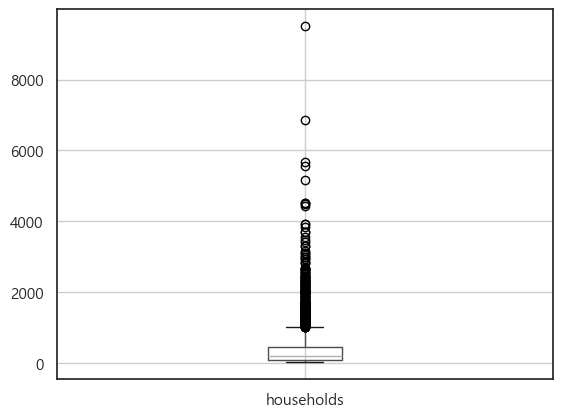

In [10]:
df.boxplot(column=['households'])
plt.show()

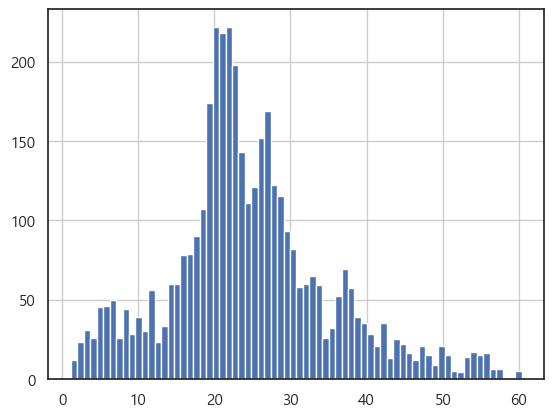

In [11]:
df['buildDate'].hist(bins=70)
plt.show()

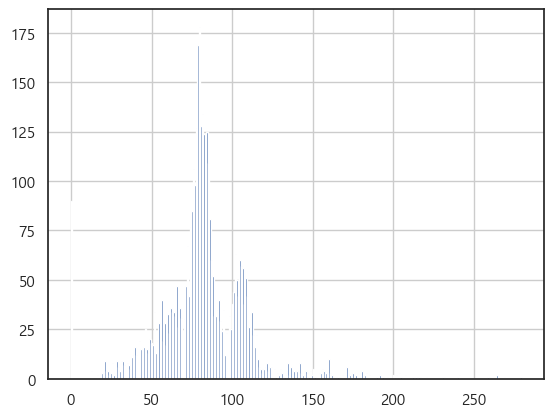

In [12]:
df['m2'].hist(bins=300)
plt.show()

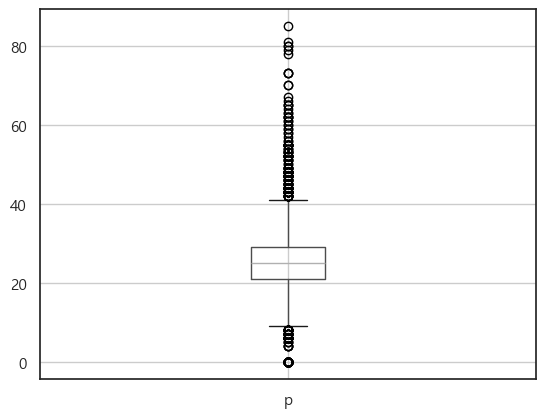

In [13]:
df.boxplot(column=['p'])
plt.show()

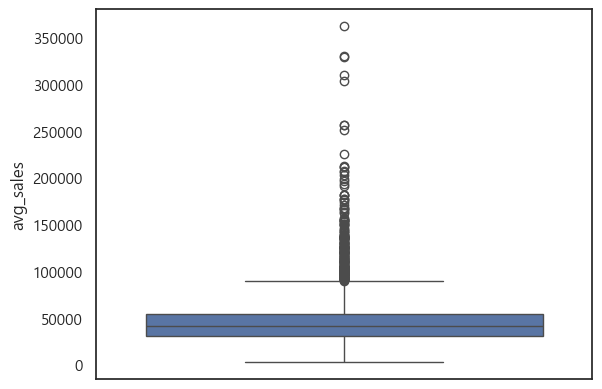

In [14]:
sns.boxplot(df['avg_sales'])
plt.show()

In [15]:
drop_df = df.drop(['lat','lng','address','city','gu','dong'], axis=1, inplace = False)
drop_df

,households,buildDate,score,m2,p,avg_sales
0,492,25.416667,4.3,139,42,61000.0
1,468,24.500000,4.1,105,32,51000.0
2,57,20.750000,4.8,86,26,40500.0
3,216,30.166667,4.8,102,31,34500.0
4,165,22.416667,4.8,91,28,40000.0
...,...,...,...,...,...,...
4016,392,22.416667,4.5,86,26,63000.0
4017,120,16.833333,4.0,106,32,20000.0
4018,92,15.750000,3.5,83,25,24000.0
4019,119,22.416667,4.3,75,23,70000.0


In [16]:
drop_df.corr()

,households,buildDate,score,m2,p,avg_sales
households,1.000000,-0.023213,0.148185,-0.111651,-0.110440,0.088917
buildDate,-0.023213,1.000000,0.084987,0.003866,0.004120,-0.331348
score,0.148185,0.084987,1.000000,0.244003,0.244928,0.098324
m2,-0.111651,0.003866,0.244003,1.000000,0.999504,0.564675
p,-0.110440,0.004120,0.244928,0.999504,1.000000,0.564547
avg_sales,0.088917,-0.331348,0.098324,0.564675,0.564547,1.000000


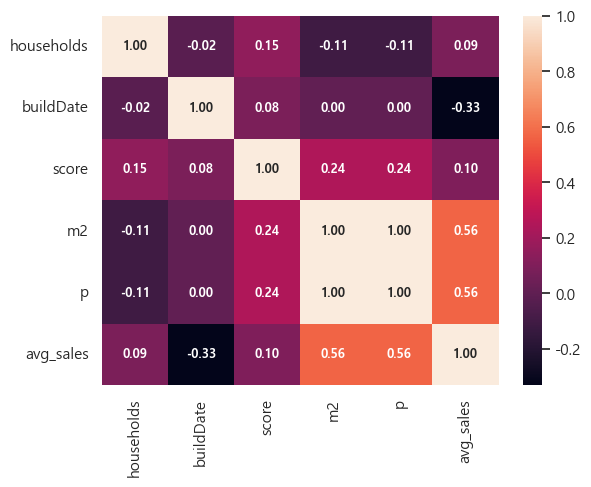

In [17]:
df_cor = drop_df.corr()
sns.heatmap(df_cor,annot=True, fmt=".2f",
            annot_kws={"size": 9, "weight": "bold"})
plt.show()

C:\Users\hyper\AppData\Local\Temp\ipykernel_7460\757880500.py:1: RuntimeWarning: Second argument 'm2' is ambiguous: could be a format string but is in 'data'; using as data.  If it was intended as data, set the format string to an empty string to suppress this warning.  If it was intended as a format string, explicitly pass the x-values as well.  Alternatively, rename the entry in 'data'.
  plt.plot('avg_sales', 'm2',


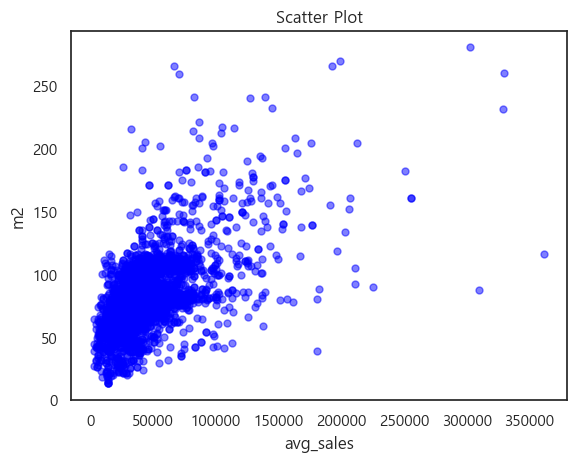

In [18]:
plt.plot('avg_sales', 'm2',
         data=df,
         linestyle='none',
         marker='o',
         markersize=5,
         color='blue',
         alpha=0.5)
plt.title('Scatter Plot')
plt.xlabel('avg_sales')
plt.ylabel('m2')
plt.show()

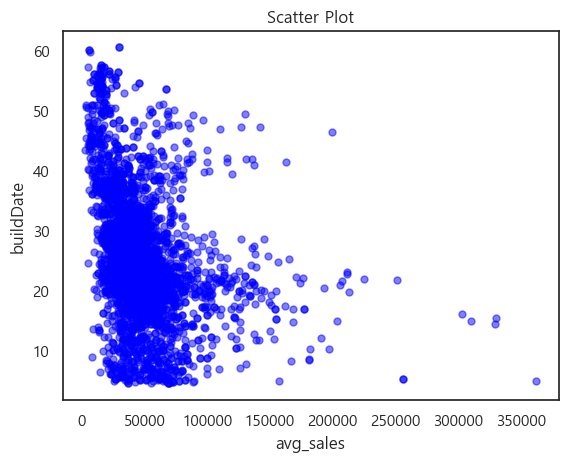

In [19]:
plt.plot('avg_sales', 'buildDate',
         data=df,
         linestyle='none',
         marker='o',
         markersize=5,
         color='blue',
         alpha=0.5)
plt.title('Scatter Plot')
plt.xlabel('avg_sales')
plt.ylabel('buildDate')
plt.show()

C:\Users\hyper\AppData\Local\Temp\ipykernel_7460\429577061.py:1: RuntimeWarning: Second argument 'p' is ambiguous: could be a format string but is in 'data'; using as data.  If it was intended as data, set the format string to an empty string to suppress this warning.  If it was intended as a format string, explicitly pass the x-values as well.  Alternatively, rename the entry in 'data'.
  plt.plot('avg_sales', 'p',


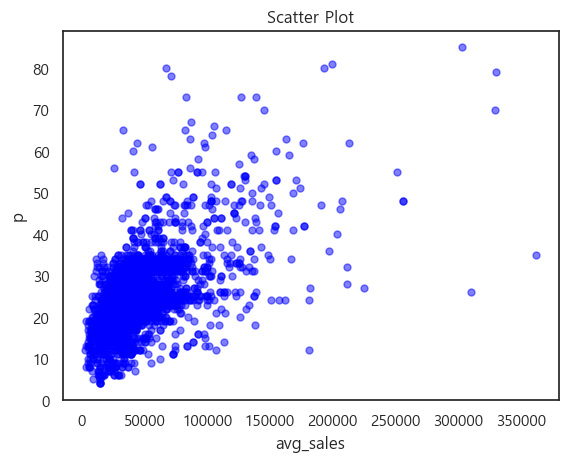

In [20]:
plt.plot('avg_sales', 'p',
         data=df,
         linestyle='none',
         marker='o',
         markersize=5,
         color='blue',
         alpha=0.5)
plt.title('Scatter Plot')
plt.xlabel('avg_sales')
plt.ylabel('p')
plt.show()

city
서울특별시    3713
대구광역시     241
광명시        33
구리시        24
의정부시        6
Name: count, dtype: int64


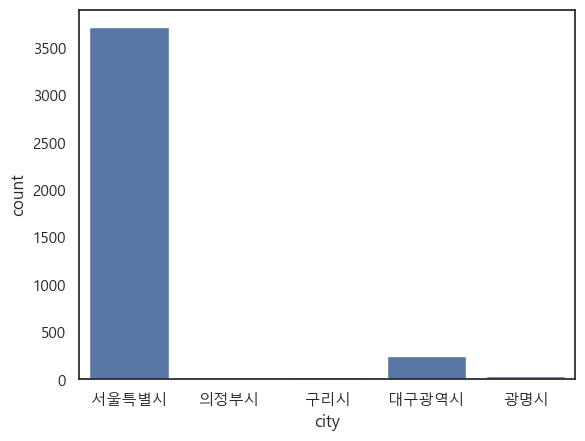

In [21]:
print(df['city'].value_counts())
sns.countplot(x = 'city', data = df)
plt.show()

dong
문래동     60
염창동     54
구로5동    48
장안1동    44
신도림동    42
        ..
묵1동      1
중곡1동     1
면목본동     1
독산2동     1
가동       1
Name: count, Length: 377, dtype: int64


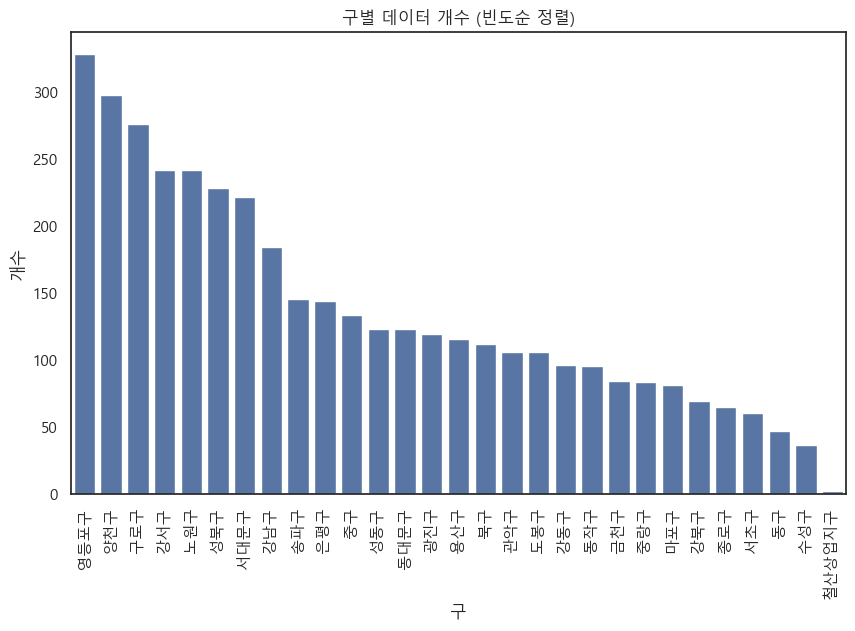

In [22]:

gu_order = df['gu'].value_counts().index
print(df['dong'].value_counts())
# 시각화
plt.figure(figsize=(10, 6))
sns.countplot(x='gu', data=df, order=gu_order)

plt.xticks(rotation=90)
plt.title('구별 데이터 개수 (빈도순 정렬)')
plt.xlabel('구')
plt.ylabel('개수')
plt.show()

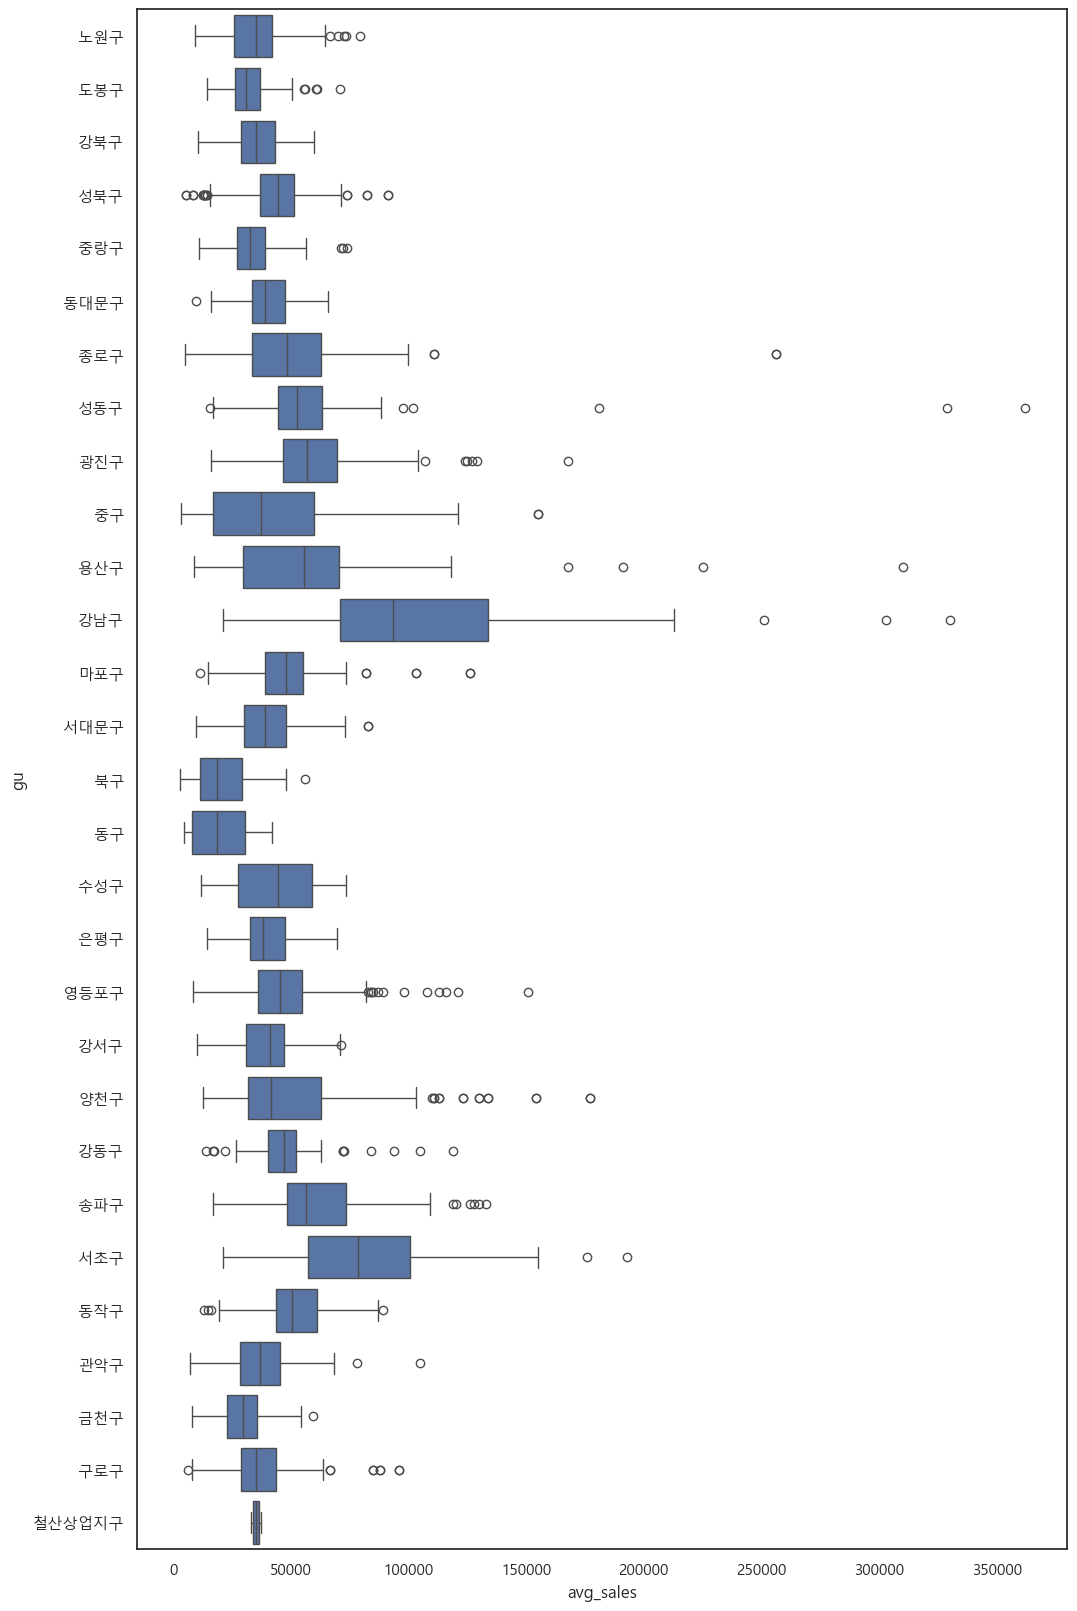

In [23]:
fig = plt.figure(figsize = (12, 20))
ax = fig.gca()
sns.boxplot(x='avg_sales', y='gu', data=df, ax=ax)
plt.show()

In [24]:
df.isnull().sum()

lat            0
lng            0
households     0
buildDate      0
score          0
m2             0
p              0
avg_sales     90
address        0
city           4
gu            61
dong          10
dtype: int64

In [25]:
# 각 city별 개수 세기
city_counts = df['city'].value_counts()

print(city_counts)

city
서울특별시    3713
대구광역시     241
광명시        33
구리시        24
의정부시        6
Name: count, dtype: int64


In [26]:
df.isnull().sum()

lat            0
lng            0
households     0
buildDate      0
score          0
m2             0
p              0
avg_sales     90
address        0
city           4
gu            61
dong          10
dtype: int64

In [27]:
df.describe()

,lat,lng,households,buildDate,score,m2,p,avg_sales
count,4021.000000,4021.000000,4021.000000,4021.000000,4021.000000,4021.000000,4021.000000,3931.000000
mean,37.450174,127.070089,376.167371,24.618192,3.437205,82.188013,24.881124,46564.945307
std,0.399840,0.397594,543.916736,10.662577,1.558044,29.548795,8.938195,27997.641529
min,35.859696,126.826620,30.000000,1.166667,0.000000,0.000000,0.000000,2700.000000
25%,37.503663,126.896831,78.000000,19.083333,3.500000,71.000000,21.000000,31000.000000
50%,37.537783,126.972067,189.000000,23.166667,4.000000,81.000000,25.000000,41500.000000
75%,37.583452,127.060411,452.000000,29.666667,4.300000,95.000000,29.000000,54500.000000
max,37.704212,128.627897,9510.000000,60.416667,5.000000,280.000000,85.000000,362000.000000


In [28]:

drop_df = df.drop(['lat','lng','address','city','gu','dong','p'], axis=1, inplace = False)
drop_df

# 숫자형만 남기기
X_vif = drop_df.select_dtypes(include=[np.number]).copy()

# inf → NaN
X_vif = X_vif.replace([np.inf, -np.inf], np.nan)

X_vif = X_vif.dropna()


In [29]:


X = X_vif  # 수치형 변수만 넣기
X = add_constant(X)

vif = pd.DataFrame()
vif["feature"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print(vif)


      feature        VIF
0       const  24.057253
1  households   1.080991
2   buildDate   1.128380
3       score   1.055785
4          m2   1.538623
5   avg_sales   1.670521


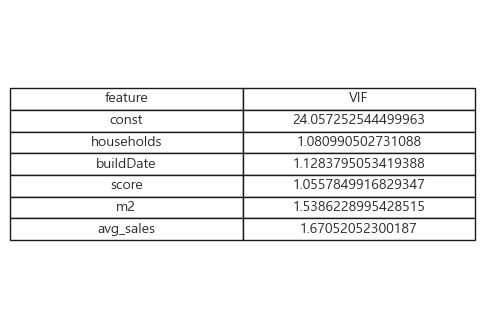

In [30]:


fig, ax = plt.subplots(figsize=(6, len(vif)*0.5 + 1))
ax.axis('off')

table = ax.table(
    cellText=vif.values,
    colLabels=vif.columns,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.3)

plt.savefig("vif_table.png", dpi=300, bbox_inches='tight')
plt.show()


In [31]:


X = df[['m2','p']].copy()  
X = add_constant(X)

vif_df = pd.DataFrame()
vif_df["feature"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_df)


  feature          VIF
0   const     8.751595
1      m2  1007.548931
2       p  1007.548931


In [32]:
df[['m2','p']].head(20)
df[['m2','p']].sample(20)
df[['m2','p']].corr()


,m2,p
m2,1.000000,0.999504
p,0.999504,1.000000


In [33]:
df.isnull().sum()

lat            0
lng            0
households     0
buildDate      0
score          0
m2             0
p              0
avg_sales     90
address        0
city           4
gu            61
dong          10
dtype: int64

<h1>모델링 모델링 모델링 모델링 모델링<h1>

<h1>모델링 모델링 모델링 모델링 모델링<h1>

<h1>모델링 모델링 모델링 모델링 모델링<h1>

[Fold 1] RMSE: 16365.752, MAE: 7457.665, MAPE: 14.408%, R²: 0.775
[Fold 2] RMSE: 19153.706, MAE: 8186.955, MAPE: 16.612%, R²: 0.715
[Fold 3] RMSE: 8928.013, MAE: 5893.122, MAPE: 13.995%, R²: 0.869
[Fold 4] RMSE: 9314.696, MAE: 6353.507, MAPE: 14.564%, R²: 0.836
[Fold 5] RMSE: 10725.267, MAE: 6835.615, MAPE: 15.953%, R²: 0.837
[Fold 6] RMSE: 11182.248, MAE: 6782.127, MAPE: 16.043%, R²: 0.848
[Fold 7] RMSE: 9381.083, MAE: 6277.792, MAPE: 15.091%, R²: 0.844
[Fold 8] RMSE: 13268.627, MAE: 6769.427, MAPE: 14.814%, R²: 0.816
[Fold 9] RMSE: 7798.486, MAE: 5715.524, MAPE: 15.128%, R²: 0.876
[Fold 10] RMSE: 12740.934, MAE: 7484.162, MAPE: 16.229%, R²: 0.774

===== [베이스 CatBoost] 10-Fold Cross-Validation 결과 =====
평균 RMSE: 11885.881 ± 3401.713
평균 MAE : 6775.590 ± 727.419
평균 MAPE: 15.284% ± 0.831
평균 R²  : 0.819 ± 0.048
0:	learn: 27395.8497784	total: 8.54ms	remaining: 10.2s
100:	learn: 12688.7243675	total: 877ms	remaining: 9.55s
200:	learn: 10595.4049052	total: 1.75s	remaining: 8.72s
300:	learn: 93

c:\Users\hyper\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\inspection\_partial_dependence.py:717: FutureWarning: The column 5 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(



=== Proxy Model Feature Importance (DecisionTree, depth=3) ===
m2            0.768573
buildDate     0.199269
lat           0.032157
lng           0.000000
households    0.000000
score         0.000000
dtype: float64


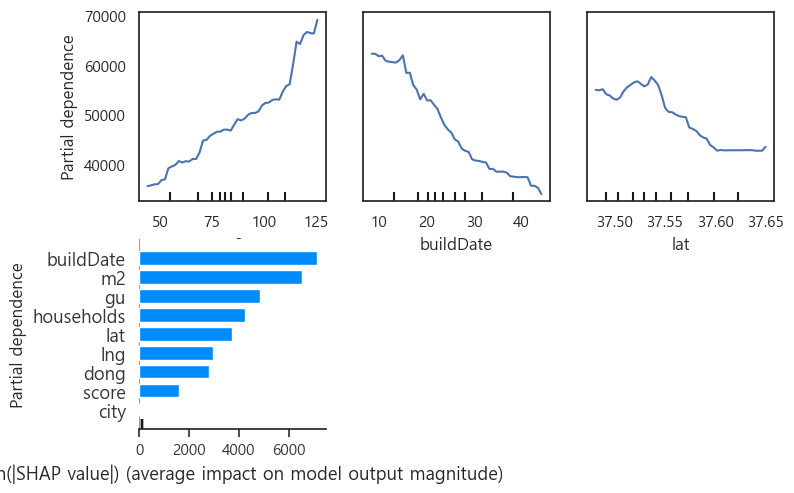

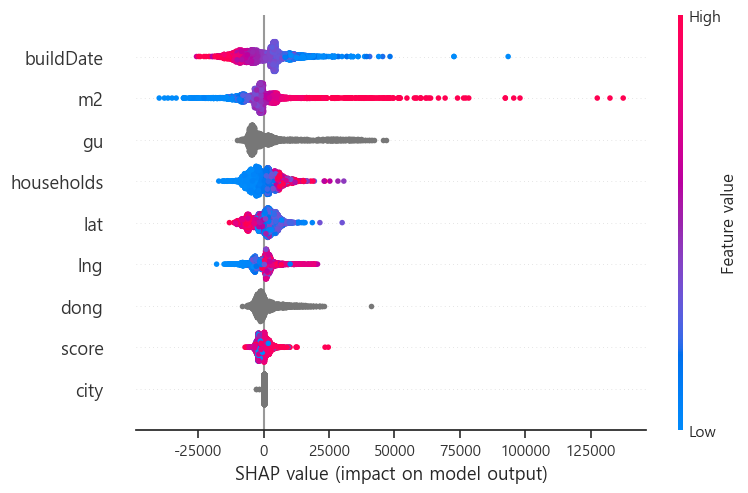

In [34]:





# 데이터 로드
df = pd.read_csv("BaseData.csv")

# 쓸 피처만 선택 
base_features = [
    'lat', 'lng',
    'households', 'buildDate', 'score', 'm2',
    'city', 'gu', 'dong'
]

X = df[base_features].copy()
y = df['avg_sales'].copy()

# 문자열 정리 + 결측치 채우기
for col in ['city', 'gu', 'dong']:
    X[col] = (
        X[col]
        .astype(str)
        .str.strip()
        .replace({'nan': None})
        .fillna('Unknown')
    )

# 범주형, 수치형 지정
cat_features = ['city', 'gu', 'dong']
num_features = [c for c in X.columns if c not in cat_features]


# -----------------------------
# 10-Fold Cross-Validation
# -----------------------------
kf = KFold(n_splits=10, shuffle=True, random_state=42)

rmse_list = []
r2_list = []
mae_list = []
mape_list = []


fold = 1
for train_idx, valid_idx in kf.split(X):
    X_tr, X_val = X.iloc[train_idx], X.iloc[valid_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[valid_idx]

    train_pool = Pool(X_tr, y_tr, cat_features=cat_features)
    valid_pool = Pool(X_val, y_val, cat_features=cat_features)

    cv_model = CatBoostRegressor(
        loss_function='RMSE',
        eval_metric='RMSE',
        depth=6,
        learning_rate=0.05,
        l2_leaf_reg=1,
        bagging_temperature=0,
        iterations=1200,
        random_state=42,
        thread_count=-1,
        verbose=False,
    )

    cv_model.fit(train_pool, eval_set=valid_pool, use_best_model=True)

    y_val_pred = cv_model.predict(valid_pool)

    rmse_fold = np.sqrt(mean_squared_error(y_val, y_val_pred))
    mae_fold  = mean_absolute_error(y_val, y_val_pred)

    mask_nonzero = y_val != 0
    mape_fold = np.mean(np.abs((y_val[mask_nonzero] - y_val_pred[mask_nonzero]) / y_val[mask_nonzero])) * 100

    r2_fold   = r2_score(y_val, y_val_pred)

    rmse_list.append(rmse_fold)
    mae_list.append(mae_fold)
    mape_list.append(mape_fold)
    r2_list.append(r2_fold)

    print(f"[Fold {fold}] RMSE: {rmse_fold:.3f}, MAE: {mae_fold:.3f}, MAPE: {mape_fold:.3f}%, R²: {r2_fold:.3f}")

    fold += 1

print("\n===== [베이스 CatBoost] 10-Fold Cross-Validation 결과 =====")
print(f"평균 RMSE: {np.mean(rmse_list):.3f} ± {np.std(rmse_list):.3f}")
print(f"평균 MAE : {np.mean(mae_list):.3f} ± {np.std(mae_list):.3f}")
print(f"평균 MAPE: {np.mean(mape_list):.3f}% ± {np.std(mape_list):.3f}")
print(f"평균 R²  : {np.mean(r2_list):.3f} ± {np.std(r2_list):.3f}")


# ======================================
# XAI: PDP, Proxy model, LIME, SHAP
# ======================================


# 전체 데이터를 이용해 최종 모델 학습
full_pool = Pool(X, y, cat_features=cat_features)

model = CatBoostRegressor(
    loss_function='RMSE',
    eval_metric='RMSE',
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=1,
    bagging_temperature=0,
    iterations=1200,
    random_state=42,
    thread_count=-1,
    verbose=100,
)

model.fit(full_pool)  # eval_set 없이 전체 데이터로 최종 학습



# Feature Importance
fi = model.get_feature_importance(train_pool)
fi_df = pd.DataFrame({'feature': X.columns, 'importance': fi}).sort_values('importance', ascending=False)
print("\n=== Feature Importance ===")
print(fi_df)



# Partial Dependence Plot (PDP)
#    - 베이스 모델에서 중요한 연속형 피처 위주로
PartialDependenceDisplay.from_estimator(
    model,
    X,  # 전체 데이터
    features=['m2', 'buildDate', 'lat', 'lng'],
    grid_resolution=50
)

# Proxy model (대리 모델: CatBoost → 작은 의사결정나무로 근사)
#    - CatBoost 예측값(y_hat)을 타깃으로,
#      수치형 피처(num_features)만 사용해 간단한 트리 학습
X_num_full = X[num_features]
y_hat_full = model.predict(X)

proxy = DecisionTreeRegressor(max_depth=3, random_state=42)
proxy.fit(X_num_full, y_hat_full)

print("\n=== Proxy Model Feature Importance (DecisionTree, depth=3) ===")
print(
    pd.Series(proxy.feature_importances_, index=num_features)
      .sort_values(ascending=False)
)


# SHAP 
shap.initjs()

shap_explainer = shap.TreeExplainer(model)
# 계산량 줄이려고 X_test 기준으로 예시
shap_values = shap_explainer.shap_values(X)

# 전체 특성 중요도 (bar summary)
shap.summary_plot(shap_values, X, plot_type='bar')

# 분포
shap.summary_plot(shap_values, X)




<h1>2모델링 모델링 모델링 모델링 모델링2<h1>

#10-fold버전

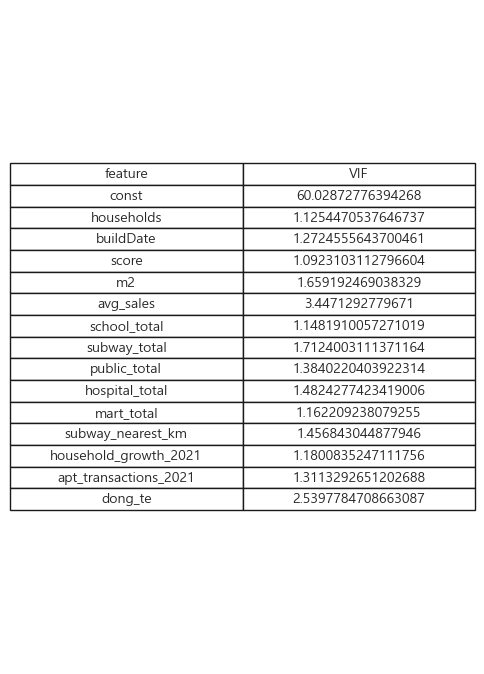

In [35]:
df = pd.read_csv('useData2.csv')
drop_df = df.drop(['lat','lng','address','city','gu','dong'], axis=1, inplace = False)
drop_df

# 1) 숫자형만 남기기
X_vif = drop_df.select_dtypes(include=[np.number]).copy()

# 2) inf → NaN
X_vif = X_vif.replace([np.inf, -np.inf], np.nan)

# 3) NaN 제거
X_vif = X_vif.dropna()

X = X_vif  # 수치형 변수만 넣기
X = add_constant(X)

vif = pd.DataFrame()
vif["feature"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

fig, ax = plt.subplots(figsize=(6, len(vif)*0.5 + 1))
ax.axis('off')

table = ax.table(
    cellText=vif.values,
    colLabels=vif.columns,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.3)

plt.savefig("vif_table.png", dpi=300, bbox_inches='tight')
plt.show()

[Fold 1] RMSE: 14778.128, MAE: 6243.708, MAPE: 11.731%, R²: 0.817
[Fold 2] RMSE: 18677.933, MAE: 7425.301, MAPE: 14.133%, R²: 0.729
[Fold 3] RMSE: 7967.201, MAE: 4922.692, MAPE: 11.508%, R²: 0.895
[Fold 4] RMSE: 8106.440, MAE: 5005.736, MAPE: 11.072%, R²: 0.876
[Fold 5] RMSE: 8327.565, MAE: 5366.741, MAPE: 12.539%, R²: 0.902
[Fold 6] RMSE: 12045.398, MAE: 6352.059, MAPE: 14.008%, R²: 0.824
[Fold 7] RMSE: 8496.170, MAE: 5103.758, MAPE: 12.277%, R²: 0.872
[Fold 8] RMSE: 12849.892, MAE: 5998.022, MAPE: 12.925%, R²: 0.827
[Fold 9] RMSE: 7789.426, MAE: 4539.340, MAPE: 11.211%, R²: 0.876
[Fold 10] RMSE: 10593.663, MAE: 5831.399, MAPE: 13.110%, R²: 0.844

===== 10-Fold Cross-Validation 평균 결과 =====
평균 RMSE : 10963.182 ± 3452.258
평균 MAE  : 5678.876 ± 818.474
평균 MAPE : 12.452% ± 1.039
평균 R²   : 0.846 ± 0.048
0:	learn: 26549.1224289	total: 12.1ms	remaining: 14.5s
100:	learn: 7858.3467032	total: 1.33s	remaining: 14.5s
200:	learn: 5739.9093266	total: 2.73s	remaining: 13.6s
300:	learn: 4431.2097921	

c:\Users\hyper\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\inspection\_partial_dependence.py:717: FutureWarning: The column 5 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(
c:\Users\hyper\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\inspection\_partial_dependence.py:717: FutureWarning: The column 2 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(



=== Proxy Model Feature Importance (DecisionTree, depth=3) ===
dong_te                  0.654250
buildDate                0.180429
m2                       0.165322
households               0.000000
lng                      0.000000
score                    0.000000
lat                      0.000000
school_total             0.000000
subway_total             0.000000
hospital_total           0.000000
public_total             0.000000
mart_total               0.000000
subway_nearest_km        0.000000
household_growth_2021    0.000000
apt_transactions_2021    0.000000
dtype: float64


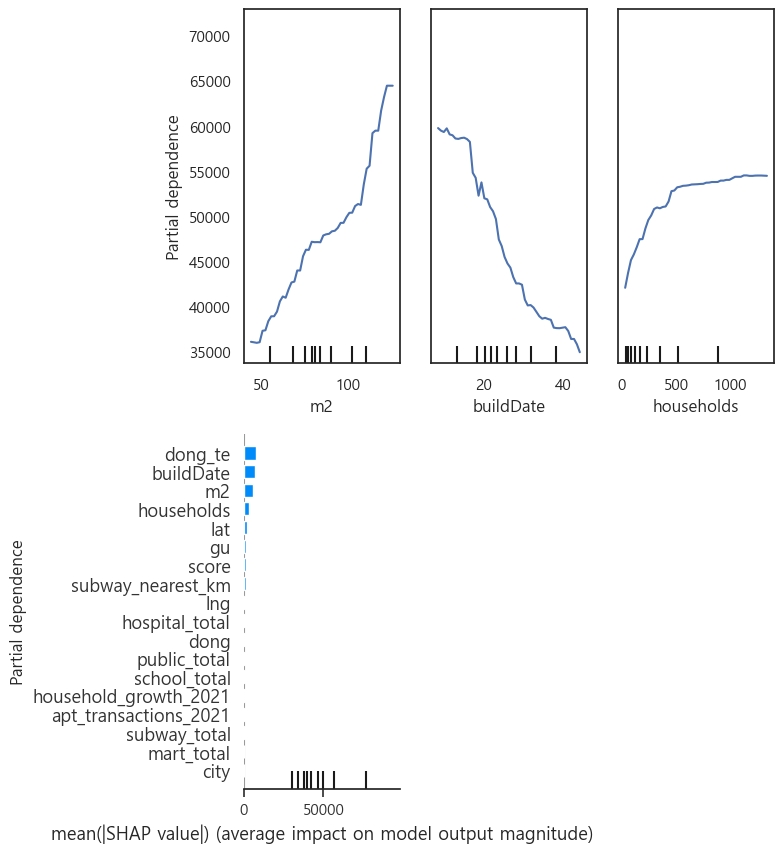

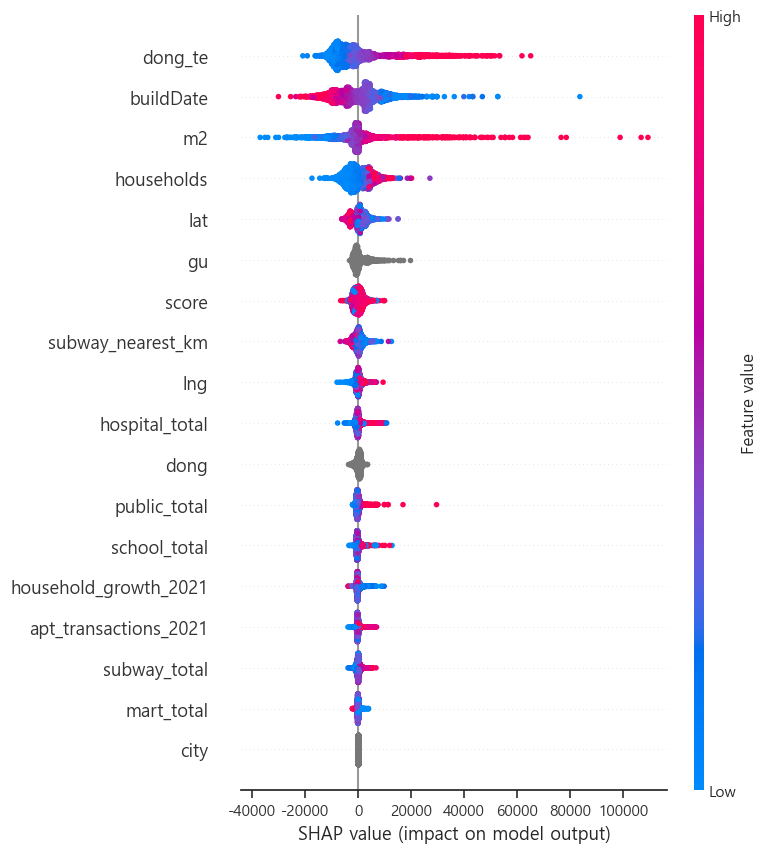

In [36]:

# 데이터 로드
df = pd.read_csv("useData2.csv")

# 피처 목록 정의
features = [
    'lat', 'lng',
    'households', 'buildDate', 'score', 'm2',
    'school_total', 'subway_total', 'public_total',
    'hospital_total', 'mart_total',
    'city', 'gu', 'dong',
    'subway_nearest_km', 'dong_te',
    'household_growth_2021', 'apt_transactions_2021'
]

X = df[features].copy()
y = df['avg_sales'].copy()

# 문자열 정리 + 결측치 처리
for col in ['city', 'gu']:
    X[col] = (
        X[col]
        .astype(str)
        .str.strip()
        .replace({'nan': None})
        .fillna('Unknown')
    )

# 범주형, 수치형 지정
cat_features = ['city', 'gu', 'dong']
num_features = [c for c in X.columns if c not in cat_features]





# --------------------------------
# 10-Fold Cross-Validation 추가
# --------------------------------

kf = KFold(n_splits=10, shuffle=True, random_state=42)

rmse_list = []
mae_list = []
mape_list = []
r2_list = []


fold = 1
for train_idx, valid_idx in kf.split(X):
    X_tr, X_val = X.iloc[train_idx], X.iloc[valid_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[valid_idx]

    train_pool = Pool(X_tr, y_tr, cat_features=cat_features)
    valid_pool = Pool(X_val, y_val, cat_features=cat_features)

    cv_model = CatBoostRegressor(
        loss_function='RMSE',
        eval_metric='RMSE',
        depth=8,                
        learning_rate=0.1,      
        l2_leaf_reg=3,          
        bagging_temperature=0,  
        iterations=1200,        
        random_state=42,
        thread_count=-1,
        verbose=False,
    )


    cv_model.fit(train_pool, eval_set=valid_pool, use_best_model=True)

    y_val_pred = cv_model.predict(valid_pool)

    rmse_fold = np.sqrt(mean_squared_error(y_val, y_val_pred))
    mae_fold  = mean_absolute_error(y_val, y_val_pred)

    mask_nonzero = y_val != 0
    mape_fold = np.mean(np.abs((y_val[mask_nonzero] - y_val_pred[mask_nonzero]) / y_val[mask_nonzero])) * 100

    r2_fold   = r2_score(y_val, y_val_pred)

    rmse_list.append(rmse_fold)
    mae_list.append(mae_fold)
    mape_list.append(mape_fold)
    r2_list.append(r2_fold)

    print(f"[Fold {fold}] RMSE: {rmse_fold:.3f}, MAE: {mae_fold:.3f}, MAPE: {mape_fold:.3f}%, R²: {r2_fold:.3f}")

    fold += 1

print("\n===== 10-Fold Cross-Validation 평균 결과 =====")
print(f"평균 RMSE : {np.mean(rmse_list):.3f} ± {np.std(rmse_list):.3f}")
print(f"평균 MAE  : {np.mean(mae_list):.3f} ± {np.std(mae_list):.3f}")
print(f"평균 MAPE : {np.mean(mape_list):.3f}% ± {np.std(mape_list):.3f}")
print(f"평균 R²   : {np.mean(r2_list):.3f} ± {np.std(r2_list):.3f}")

# ======================================
#  추가 모델 해석(Explainability)
# ======================================


# 전체 데이터를 이용해 최종 모델 학습
full_pool = Pool(X, y, cat_features=cat_features)

model = CatBoostRegressor(
    loss_function='RMSE',
    eval_metric='RMSE',
    depth=8,                
    learning_rate=0.1,      
    l2_leaf_reg=3,         
    bagging_temperature=0,  
    iterations=1200,       
    random_state=42,
    thread_count=-1,
    verbose=100,
)


model.fit(full_pool)  # eval_set 없이 전체 데이터로 최종 학습


# Feature Importance
fi = model.get_feature_importance(train_pool)
fi_df = pd.DataFrame({'feature': X.columns, 'importance': fi}).sort_values('importance', ascending=False)
print("\n=== Feature Importance ===")
print(fi_df)

# ======================================
# XAI: PDP, Proxy model, LIME, SHAP
# ======================================

# Partial Dependence Plot (PDP)
#   
PartialDependenceDisplay.from_estimator(
    model,
    X,  # 전체 데이터
    features=['m2', 'buildDate', 'households', 'dong_te'],
    grid_resolution=50
)



# 2) Proxy model 
X_num_full = X[num_features]          # 수치형 피처만 사용
y_hat_full = model.predict(X)        # CatBoost 예측값

proxy = DecisionTreeRegressor(max_depth=3, random_state=42)
proxy.fit(X_num_full, y_hat_full)

print("\n=== Proxy Model Feature Importance (DecisionTree, depth=3) ===")
print(
    pd.Series(proxy.feature_importances_, index=num_features)
      .sort_values(ascending=False)
)


# 4) SHAP 
shap.initjs()

shap_explainer = shap.TreeExplainer(model)
# 계산량 줄이려고 X_test 기준으로 예시
shap_values = shap_explainer.shap_values(X)

# 전체 특성 중요도 (bar summary)
shap.summary_plot(shap_values, X, plot_type='bar')

# 분포
shap.summary_plot(shap_values, X)

